In [1]:
!pip install seaborn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys
!{sys.executable} -m pip install scikit-learn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

df = pd.read_csv(
    r"C:\Users\mariam\Desktop\classification\loan_approval_dataset.csv"
)

df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
df.shape

(4269, 13)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 531.6 KB


In [6]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [7]:
df.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df = df.drop("loan_id", axis=1)

In [10]:
print(df.columns.tolist())

[' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']


In [11]:
df.columns = df.columns.str.strip()

In [12]:
df["loan_status"].value_counts()

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

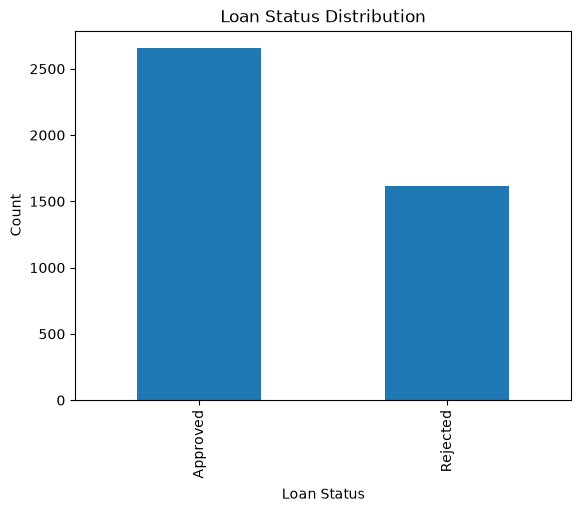

In [13]:
df["loan_status"].value_counts().plot(kind="bar")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.show()

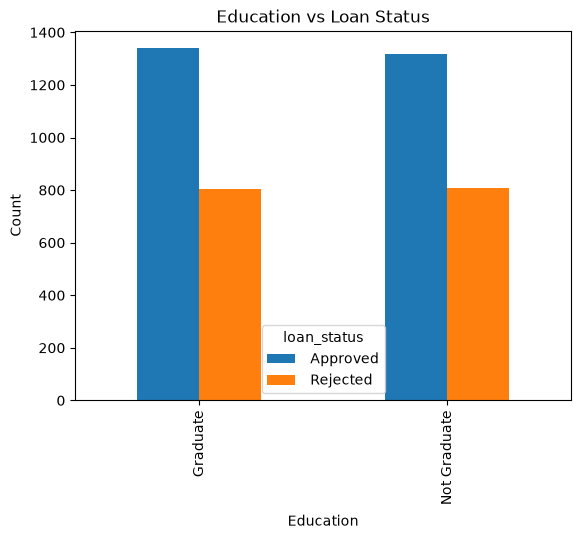

In [14]:
pd.crosstab(df["education"], df["loan_status"]).plot(kind="bar")

plt.title("Education vs Loan Status")
plt.xlabel("Education")
plt.ylabel("Count")
plt.show()

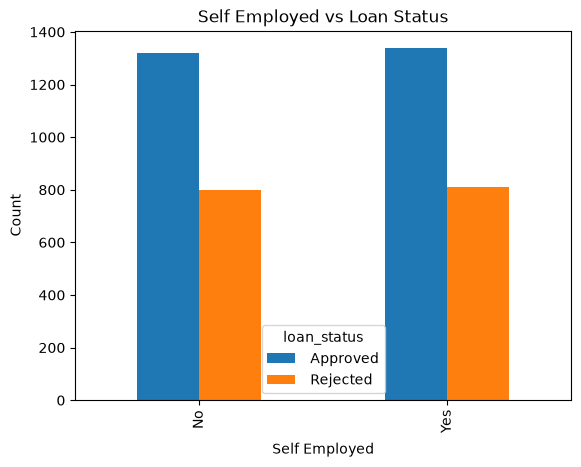

In [15]:
pd.crosstab(df["self_employed"], df["loan_status"]).plot(kind="bar")

plt.title("Self Employed vs Loan Status")
plt.xlabel("Self Employed")
plt.ylabel("Count")
plt.show()

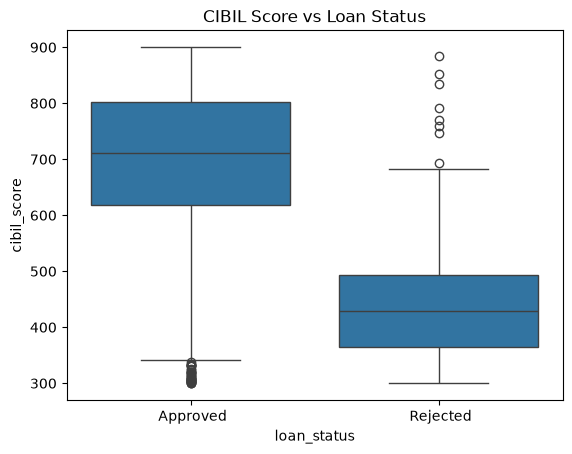

In [16]:
sns.boxplot(x="loan_status", y="cibil_score", data=df)

plt.title("CIBIL Score vs Loan Status")
plt.show()

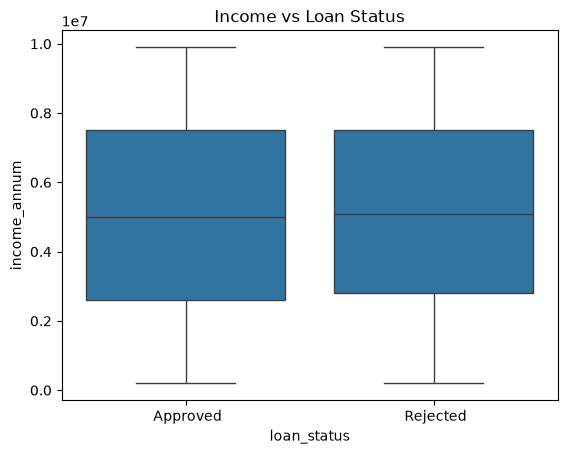

In [17]:
sns.boxplot(x="loan_status", y="income_annum", data=df)

plt.title("Income vs Loan Status")
plt.show()

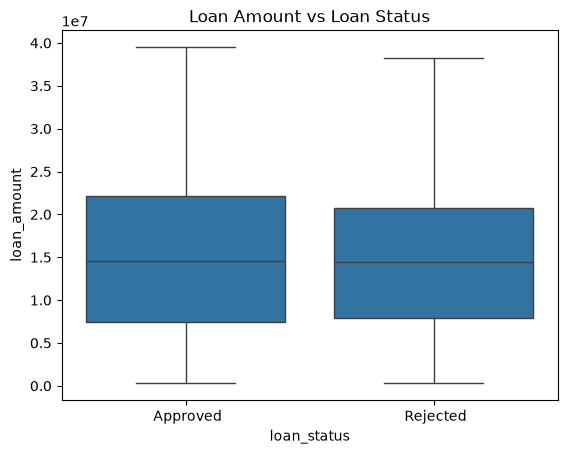

In [18]:
sns.boxplot(x="loan_status", y="loan_amount", data=df)

plt.title("Loan Amount vs Loan Status")
plt.show()

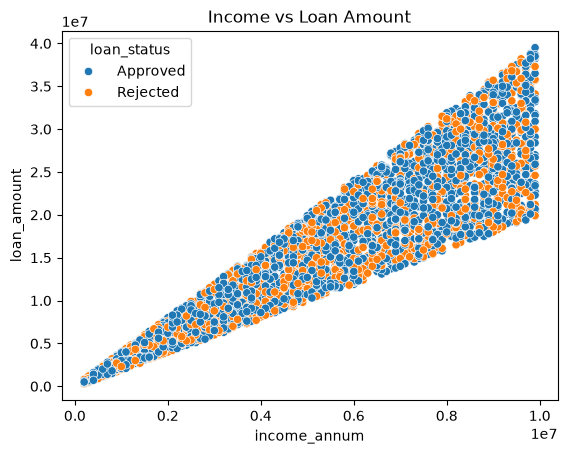

In [19]:
sns.scatterplot(
    x="income_annum",
    y="loan_amount",
    hue="loan_status",
    data=df
)

plt.title("Income vs Loan Amount")
plt.show()

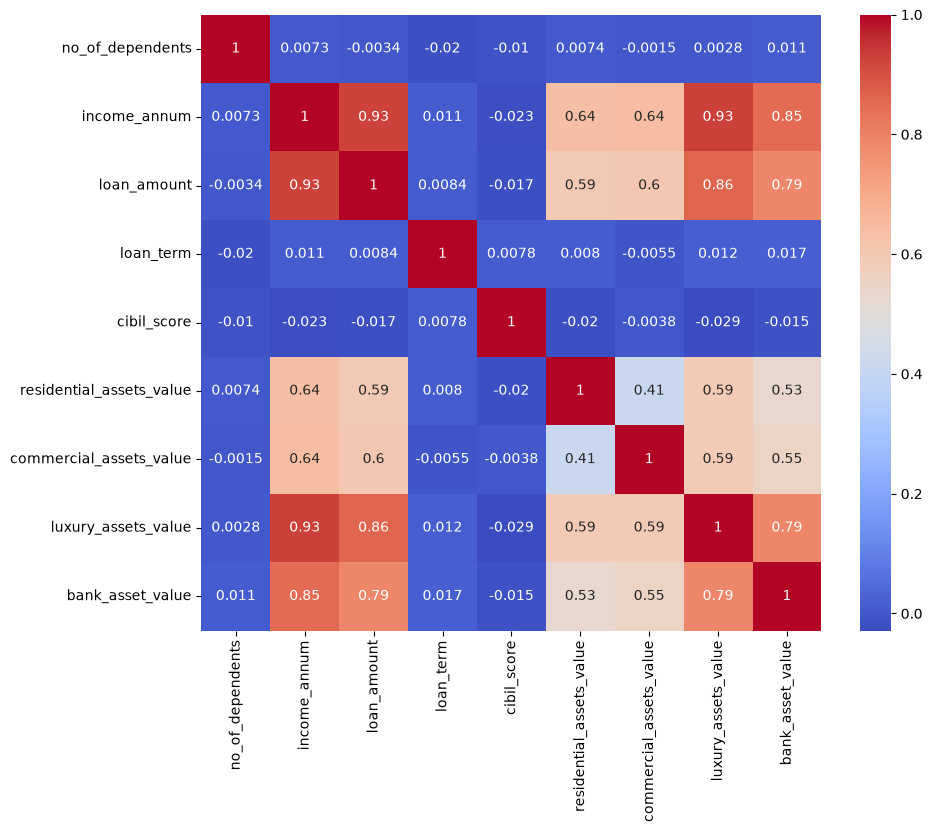

In [20]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

In [24]:
df["education"] = df["education"].map({
    "Graduate": 1,
    "Not Graduate": 0
})

df["self_employed"] = df["self_employed"].map({
    "Yes": 1,
    "No": 0
})

df["loan_status"] = df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

In [25]:
df["loan_income_ratio"] = df["loan_amount"] / df["income_annum"]

In [26]:
df["income_per_dependent"] = df["income_annum"] / (df["no_of_dependents"] + 1)

In [34]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

In [29]:
from sklearn.model_selection import train_test_split

In [40]:
df['education'] = df['education'].str.strip()
df['self_employed'] = df['self_employed'].str.strip()

df['education'] = df['education'].map({
    'Graduate': 1,
    'Not Graduate': 0
})

df['self_employed'] = df['self_employed'].map({
    'Yes': 1,
    'No': 0
})

In [41]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [49]:
df['loan_status'] = df['loan_status'].str.strip()

df['loan_status'] = df['loan_status'].map({
    'Approved': 1,
    'Rejected': 0
})

In [50]:
print(df['loan_status'].value_counts())
print(df['loan_status'].unique())

loan_status
1    2656
0    1613
Name: count, dtype: int64
[1 0]


In [51]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

In [52]:
print(X.select_dtypes(include='object').columns)

Index([], dtype='str')


In [42]:
print(X_train.select_dtypes(include='object').columns)

Index([], dtype='str')


In [43]:
log_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [25]:
from sklearn.linear_model import LogisticRegression

In [26]:
model = LogisticRegression()

In [28]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']


In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (3415, 11)
X_test: (854, 11)


In [59]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [54]:
log_model = LogisticRegression(
    max_iter=1000
)

log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)
y_proba = log_model.predict_proba(X_test)[:, 1]

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

Accuracy: 0.8032786885245902
Precision: 0.7941653160453809
Recall: 0.9227871939736346
F1: 0.8536585365853658
ROC-AUC: 0.883128392599978


In [56]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.61      0.70       323
           1       0.79      0.92      0.85       531

    accuracy                           0.80       854
   macro avg       0.81      0.76      0.78       854
weighted avg       0.81      0.80      0.80       854



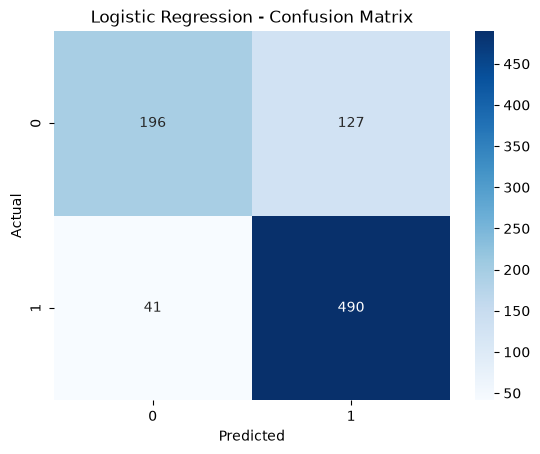

In [57]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [61]:

from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(
    log_model,
    X_train,
    y_train,
    cv=5,
    scoring='f1'
)

print("CV Scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean())

CV Scores: [0.85313175 0.85620198 0.83060109 0.82751092 0.85776805]
Mean CV F1: 0.8450427575507822


In [66]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

lasso_results = []

for alpha in alpha_values:

    C = 1 / alpha

    model = LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=C,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    lasso_results.append([
        alpha,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ])

lasso_results = pd.DataFrame(
    lasso_results,
    columns=["Alpha", "Accuracy", "Precision", "Recall", "F1"]
)

lasso_results
    

c:\Users\mariam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\mariam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\mariam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default

,Alpha,Accuracy,Precision,Recall,F1
0,0.001,0.912178,0.917582,0.943503,0.930362
1,0.010,0.912178,0.917582,0.943503,0.930362
2,0.100,0.912178,0.917582,0.943503,0.930362
3,1.000,0.911007,0.917431,0.941620,0.929368
4,10.000,0.911007,0.914390,0.945386,0.929630
5,100.000,0.870023,0.862069,0.941620,0.900090


In [67]:
best_lasso = lasso_results.loc[
    lasso_results["F1"].idxmax()
]

print("Best Alpha:", best_lasso["Alpha"])
print("Best F1:", best_lasso["F1"])

Best Alpha: 0.001
Best F1: 0.9303621169916435


In [68]:
ridge_results = []

for alpha in alpha_values:

    C = 1 / alpha

    model = LogisticRegression(
        penalty="l2",
        C=C,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    ridge_results.append([
        alpha,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ])

ridge_results = pd.DataFrame(
    ridge_results,
    columns=["Alpha", "Accuracy", "Precision", "Recall", "F1"]
)

ridge_results

c:\Users\mariam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\mariam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn

,Alpha,Accuracy,Precision,Recall,F1
0,0.001,0.803279,0.794165,0.922787,0.853659
1,0.010,0.803279,0.794165,0.922787,0.853659
2,0.100,0.803279,0.794165,0.922787,0.853659
3,1.000,0.803279,0.794165,0.922787,0.853659
4,10.000,0.820843,0.816054,0.919021,0.864482
5,100.000,0.803279,0.794165,0.922787,0.853659


In [69]:
best_ridge = ridge_results.loc[
    ridge_results["F1"].idxmax()
]

print("Best Alpha:", best_ridge["Alpha"])
print("Best F1:", best_ridge["F1"])

Best Alpha: 10.0
Best F1: 0.8644818423383526


In [70]:
best_alpha_lasso = best_lasso["Alpha"]
best_alpha_ridge = best_ridge["Alpha"]

In [71]:
lasso_model = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    C=1 / best_alpha_lasso,
    max_iter=1000
)

ridge_model = LogisticRegression(
    penalty="l2",
    C=1 / best_alpha_ridge,
    max_iter=1000
)

lasso_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)

c:\Users\mariam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\mariam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\mariam\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(0.1)
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [72]:
models = {
    "Logistic Regression": log_model,
    "Lasso": lasso_model,
    "Ridge": ridge_model
}

comparison = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    comparison.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ])

comparison = pd.DataFrame(
    comparison,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

comparison

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.803279,0.794165,0.922787,0.853659
1,Lasso,0.912178,0.917582,0.943503,0.930362
2,Ridge,0.820843,0.816054,0.919021,0.864482


In [73]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

In [74]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [75]:
models = {
    "Logistic Regression": log_model,
    "Lasso": lasso_model,
    "Ridge": ridge_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ])

comparison = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.803279,0.794165,0.922787,0.853659
1,Lasso,0.912178,0.917582,0.943503,0.930362
2,Ridge,0.820843,0.816054,0.919021,0.864482
3,Decision Tree,0.981265,0.984934,0.984934,0.984934
4,Random Forest,0.980094,0.983083,0.984934,0.984008


In [76]:
comparison.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
3,Decision Tree,0.981265,0.984934,0.984934,0.984934
4,Random Forest,0.980094,0.983083,0.984934,0.984008
1,Lasso,0.912178,0.917582,0.943503,0.930362
2,Ridge,0.820843,0.816054,0.919021,0.864482
0,Logistic Regression,0.803279,0.794165,0.922787,0.853659


In [77]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

models = {
    "Logistic Regression": log_model,
    "Lasso": lasso_model,
    "Ridge": ridge_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    # Train predictions
    y_train_pred = model.predict(X_train)

    # Test predictions
    y_test_pred = model.predict(X_test)

    results.append([
        name,

        # Train
        accuracy_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred),

        # Test
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred)
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Train Accuracy",
        "Train Recall",
        "Train Precision",
        "Train F1",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1"
    ]
)

results_df

,Model,Train Accuracy,Train Recall,Train Precision,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Logistic Regression,0.792679,0.911059,0.788595,0.845415,0.803279,0.794165,0.922787,0.853659
1,Lasso,0.916837,0.935059,0.931552,0.933302,0.912178,0.917582,0.943503,0.930362
2,Ridge,0.810835,0.912941,0.807997,0.857269,0.820843,0.816054,0.919021,0.864482
3,Decision Tree,1.000000,1.000000,1.000000,1.000000,0.981265,0.984934,0.984934,0.984934
4,Random Forest,1.000000,1.000000,1.000000,1.000000,0.980094,0.983083,0.984934,0.984008


In [80]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dt = DecisionTreeClassifier(random_state=42)

dt_params = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [10, 20, 30],
    "min_samples_leaf": [5, 10, 15, 20]
}

dt_grid = GridSearchCV(
    dt,
    dt_params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Parameters:")
print(dt_grid.best_params_)

print("Best CV F1:")
print(dt_grid.best_score_)

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 15, 'min_samples_split': 10}
Best CV F1:
0.982378459410176


In [81]:
dt_final = dt_grid.best_estimator_

dt_train_pred = dt_final.predict(X_train)
dt_test_pred = dt_final.predict(X_test)

In [82]:
print("Train F1:", f1_score(y_train, dt_train_pred))
print("Test F1 :", f1_score(y_test, dt_test_pred))

Train F1: 0.9872881355932204
Test F1 : 0.985941893158388


In [83]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    random_state=42
)

rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [5, 7, 10],
    "min_samples_split": [10, 20],
    "min_samples_leaf": [5, 10]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Parameters:")
print(rf_grid.best_params_)

print("Best CV F1:")
print(rf_grid.best_score_)

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 20, 'n_estimators': 200}
Best CV F1:
0.9792947125092546


In [84]:
rf_final = rf_grid.best_estimator_

rf_train_pred = rf_final.predict(X_train)
rf_test_pred = rf_final.predict(X_test)

print("Train F1:", f1_score(y_train, rf_train_pred))
print("Test F1 :", f1_score(y_test, rf_test_pred))

Train F1: 0.9960103262145036
Test F1 : 0.9868667917448405


In [85]:
models = {
    "Logistic Regression": log_model,
    "Lasso": lasso_model,
    "Ridge": ridge_model,
    "Decision Tree": dt_final,
    "Random Forest": rf_final
}

In [86]:
results = []

for name, model in models.items():

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append([
        name,

        accuracy_score(y_train, train_pred),
        recall_score(y_train, train_pred),
        precision_score(y_train, train_pred),
        f1_score(y_train, train_pred),

        accuracy_score(y_test, test_pred),
        precision_score(y_test, test_pred),
        recall_score(y_test, test_pred),
        f1_score(y_test, test_pred)
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Train Accuracy",
        "Train Recall",
        "Train Precision",
        "Train F1",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1"
    ]
)

results_df.round(4)

,Model,Train Accuracy,Train Recall,Train Precision,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Logistic Regression,0.7927,0.9111,0.7886,0.8454,0.8033,0.7942,0.9228,0.8537
1,Lasso,0.9168,0.9351,0.9316,0.9333,0.9122,0.9176,0.9435,0.9304
2,Ridge,0.8108,0.9129,0.8080,0.8573,0.8208,0.8161,0.9190,0.8645
3,Decision Tree,0.9842,0.9868,0.9878,0.9873,0.9824,0.9813,0.9906,0.9859
4,Random Forest,0.9950,0.9986,0.9934,0.9960,0.9836,0.9832,0.9906,0.9869


In [87]:
results = []

for name, model in models.items():

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append([
        name,

        accuracy_score(y_train, train_pred),
        recall_score(y_train, train_pred),
        precision_score(y_train, train_pred),
        f1_score(y_train, train_pred),

        accuracy_score(y_test, test_pred),
        precision_score(y_test, test_pred),
        recall_score(y_test, test_pred),
        f1_score(y_test, test_pred)
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Train Accuracy",
        "Train Recall",
        "Train Precision",
        "Train F1",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1"
    ]
)

results_df.round(4)

,Model,Train Accuracy,Train Recall,Train Precision,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Logistic Regression,0.7927,0.9111,0.7886,0.8454,0.8033,0.7942,0.9228,0.8537
1,Lasso,0.9168,0.9351,0.9316,0.9333,0.9122,0.9176,0.9435,0.9304
2,Ridge,0.8108,0.9129,0.8080,0.8573,0.8208,0.8161,0.9190,0.8645
3,Decision Tree,0.9842,0.9868,0.9878,0.9873,0.9824,0.9813,0.9906,0.9859
4,Random Forest,0.9950,0.9986,0.9934,0.9960,0.9836,0.9832,0.9906,0.9869
